In [1]:
%%time
from tqdm import tqdm
import datashader as ds
import datashader.transfer_functions as tf
import matplotlib.dates as mdates
import pymannkendall as mk
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import xskillscore as xs
import pandas as pd
import numpy as np
import xarray as xr
import matplotlib as mpl
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from matplotlib.colors import to_hex
import matplotlib.ticker as ticker
import cartopy.crs as ccrs
import cartopy.feature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import os,sys,glob
sys.path.insert(0,'/home/mingyu_seong/Works/func/python')
import mg
import warnings

def extract_seasonal_data(data, isea, sdate, edate):
    tmp0 = data
    if( isea == 'ANN' ):
        odata = tmp0.sel(time=slice(sdate,edate))
    else:
        tmp1 = tmp0[(tmp0['time.season'] == isea),:,:] 
        if( isea == 'DJF' ):
            odata = tmp1[:,:,:].sel(time=slice(sdate[0:4]+'-12-01',edate[0:4]+'-02-28'))
        elif( isea == 'MAM' ):
            odata = tmp1[:,:,:].sel(time=slice(sdate,edate))
        else:
            odata = tmp1[:,:,:].sel(time=slice(sdate,edate))
        del tmp1
    del tmp0
    return odata

CPU times: user 4.13 s, sys: 143 ms, total: 4.27 s
Wall time: 1.99 s


In [2]:
#--- Random seed
rs = 42

dic_season = {'MAM':4, 'JJA':7, 'SON':10, 'DJF':12}

#--- Input period
sdate = '2001-01-01'
edate = '2024-12-31'

#--- Analysis period
# 1) Fold 03
csdate = '2007-01-01'
cedate = '2008-12-31'

#--- Directories
idir = '../../../_nc/prediction/OBS/Reco/variation/'

#--- Read variation
fin = 'predicted_Reco_8day_LGBM_' + sdate.replace('-','') + '-' + edate.replace('-','') + '_seed' + str(rs)+'.nc'
ncid = xr.open_dataset(idir+fin)
ncid = ncid.convert_calendar('noleap')
lon = ncid['lon']
lat = ncid['lat']
weights = np.cos(np.deg2rad(ncid['lat']))
weights.name = "weights"
pred = ncid['pred'].sel(time=slice(csdate,cedate))
labl = ncid['raw'].sel(time=slice(csdate,cedate))
ncid.close() ; del ncid
nlon = len(lon)
nlat = len(lat)

#--- Remove 2024.12.26 (It is not 8-day sum [26-31; 6-day])
mask_day = (labl['time'].dt.year == 2024) & \
           (labl['time'].dt.month == 12) & \
           (labl['time'].dt.day == 26)
pred = pred.where(~mask_day)
labl = labl.where(~mask_day)

### Seasonal correlation map

ANN | Mean Corr: 0.9919
MAM | Mean Corr: 0.9819
JJA | Mean Corr: 0.6528
SON | Mean Corr: 0.9914
DJF | Mean Corr: 0.8871


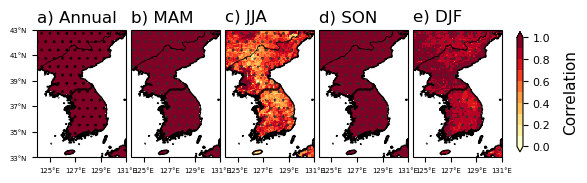

In [3]:
warnings.filterwarnings('ignore', category=RuntimeWarning)
#--- plotting option
crs = ccrs.PlateCarree(central_longitude=0)
inner_grid = gridspec.GridSpec(1, 5, wspace=0.05, hspace=0.1)
fig = plt.figure(figsize=(6,3))

#--- Scales
corr_min = 0. ; corr_max = 1
corr_lev = np.linspace(corr_min,corr_max,int((corr_max-corr_min)/0.1+1))
corr_tick= np.linspace(corr_min,corr_max,int((corr_max-corr_min)/0.2+1)) 
corr_cmap = mpl.cm.YlOrRd #coolwarm
corr_norm = mpl.colors.BoundaryNorm(corr_lev,corr_cmap.N,extend='neither')

diff_min = -0.1 ; diff_max = 0.1
diff_lev = np.linspace(diff_min,diff_max,int((diff_max-diff_min)/0.005+1))
diff_tick= np.linspace(diff_min,diff_max,int((diff_max-diff_min)/0.05+1)) 
diff_cmap = mpl.cm.coolwarm
diff_norm = mpl.colors.BoundaryNorm(diff_lev,diff_cmap.N,extend='neither')

pcnt = 0
for isea in ['ANN','MAM','JJA','SON','DJF']:
    #--- Initialization
    corr = xr.DataArray(data=np.zeros((nlat,nlon)))
    pval = xr.DataArray(data=np.zeros((nlat,nlon)))
    pmask = np.zeros((nlat,nlon))
    pmask[:,:] = np.nan
    
    #--- Extract season
    pred_val = extract_seasonal_data(pred, isea, csdate, cedate)
    real_val = extract_seasonal_data(labl, isea, csdate, cedate)
    
    #--- Correlation
    corr[:,:] = xs.pearson_r(real_val[:,:,:],pred_val[:,:,:], dim='time',skipna=True).data
    pval[:,:] = xs.pearson_r_p_value(real_val[:,:,:],pred_val[:,:,:], dim='time',skipna=True).data
    pmask[pval <= 0.05] = 1
    # pmask[corr >= 0.5] = 1

    # 1) Without
    ax0 = fig.add_subplot(inner_grid[pcnt],projection=crs)
    plt0 = ax0.pcolormesh(lon, lat, corr, 
                          shading='nearest',transform=ccrs.PlateCarree(),cmap=corr_cmap,norm=corr_norm)
    plt1 = ax0.pcolor(lon, lat, np.squeeze(pmask),shading='nearest',hatch='..',alpha=0.)
    mpl.rcParams['hatch.linewidth'] = 0.8
    mpl.rcParams['hatch.color'] = '#2f2f2f'
    ax0.coastlines(resolution='10m',linewidth=1)
    ax0.set_extent((124, 131, 33, 43),crs=crs)
    ax0.add_feature(cartopy.feature.BORDERS.with_scale('10m'), linewidth=0.5, edgecolor='black')
    if pcnt == 0  or pcnt == 5 or pcnt == 10 or pcnt == 15 :
        ax0.set_yticks(np.linspace(33, 43, 6), crs=ccrs.PlateCarree())
        lat_formatter = LatitudeFormatter()
        ax0.yaxis.set_major_formatter(lat_formatter)
    if pcnt >= 0:
        ax0.set_xticks(np.linspace(125, 131, 4),crs=ccrs.PlateCarree())
        lon_formatter = LongitudeFormatter(zero_direction_label=True)
        ax0.xaxis.set_major_formatter(lon_formatter)
    ax0.tick_params(axis='x', labelsize=5)
    ax0.tick_params(axis='y', labelsize=5)
    if pcnt == 0: 
        ax0.set_title('a) Annual' ,loc="left",fontsize=12)
    elif pcnt == 1: 
        ax0.set_title('b) MAM' ,loc="left",fontsize=12)
    elif pcnt == 2: 
        ax0.set_title('c) JJA' ,loc="left",fontsize=12)
    elif pcnt == 3: 
        ax0.set_title('d) SON' ,loc="left",fontsize=12)
    elif pcnt == 4: 
        ax0.set_title('e) DJF' ,loc="left",fontsize=12)
    if pcnt == 0:
        cbar_ax = fig.add_axes([0.925, 0.30, 0.01, 0.40])
        cbar = fig.colorbar(plt0,cax=cbar_ax,orientation="vertical",
                            ticks=corr_tick, extend="both")
        cbar.minorticks_off()
        cbar.ax.tick_params(labelsize=8)
        cbar_label = 'Correlation'
        cbar.set_label(cbar_label,loc="center",fontsize=11,labelpad=9)

    #--- Spatial mean nRMSE
    print(f'{isea:3s} | Mean Corr: {np.nanmean(corr):.4f}')
    
    pcnt += 1
    del pred_val, real_val, corr, pval, pmask

plt.show()
warnings.filterwarnings('default', category=RuntimeWarning)

### Seasonal RMSE map

ANN | Mean nRMSE: 0.1317
MAM | Mean nRMSE: 0.2323
JJA | Mean nRMSE: 0.8376
SON | Mean nRMSE: 0.1419
DJF | Mean nRMSE: 0.5628


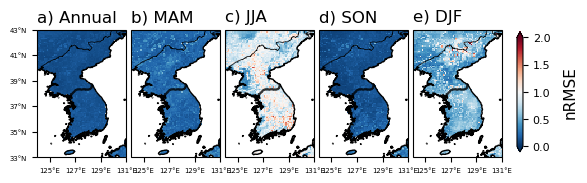

In [4]:
#--- plotting option
crs = ccrs.PlateCarree(central_longitude=0)
inner_grid = gridspec.GridSpec(1, 5, wspace=0.05, hspace=0.1)
fig = plt.figure(figsize=(6,3))

#--- Scales
corr_min = 0. ; corr_max = 2
corr_lev = np.linspace(corr_min,corr_max,int((corr_max-corr_min)/0.1+1))
corr_tick= np.linspace(corr_min,corr_max,int((corr_max-corr_min)/0.5+1)) 
# corr_cmap = mpl.cm.YlOrRd #coolwarm
# corr_norm = mpl.colors.BoundaryNorm(corr_lev,corr_cmap.N,extend='neither')
corr_cmap = mpl.cm.RdBu_r
corr_norm = mpl.colors.TwoSlopeNorm(vmin=corr_min, vcenter=1., vmax=corr_max)

pcnt = 0
for isea in ['ANN','MAM','JJA','SON','DJF']:
    #--- Initialization
    rmse = xr.DataArray(data=np.zeros((nlat,nlon)))

    #--- Extract season
    pred_val = extract_seasonal_data(pred, isea, csdate, cedate)
    real_val = extract_seasonal_data(labl, isea, csdate, cedate)

    #--- Standard deviation of OBS
    std_val = real_val.std(dim='time', skipna=True).data
    
    #--- RMSE
    rmse[:,:] = xs.rmse(real_val[:,:,:],pred_val[:,:,:], dim='time',skipna=True).data

    #--- Normalized RMSE
    nrmse = rmse / std_val

    #--- Plots
    ax0 = fig.add_subplot(inner_grid[pcnt],projection=crs)
    plt0 = ax0.pcolormesh(lon, lat, nrmse, 
                          shading='nearest',transform=ccrs.PlateCarree(),cmap=corr_cmap,norm=corr_norm)
    ax0.coastlines(resolution='10m',linewidth=1)
    ax0.set_extent((124, 131, 33, 43),crs=crs)
    ax0.add_feature(cartopy.feature.BORDERS.with_scale('10m'), linewidth=0.5, edgecolor='black')
    if pcnt == 0  or pcnt == 5 or pcnt == 10 or pcnt == 15 :
        ax0.set_yticks(np.linspace(33, 43, 6), crs=ccrs.PlateCarree())
        lat_formatter = LatitudeFormatter()
        ax0.yaxis.set_major_formatter(lat_formatter)
    if pcnt >= 0:
        ax0.set_xticks(np.linspace(125, 131, 4),crs=ccrs.PlateCarree())
        lon_formatter = LongitudeFormatter(zero_direction_label=True)
        ax0.xaxis.set_major_formatter(lon_formatter)
    ax0.tick_params(axis='x', labelsize=5)
    ax0.tick_params(axis='y', labelsize=5)
    if pcnt == 0: 
        ax0.set_title('a) Annual' ,loc="left",fontsize=12)
    elif pcnt == 1: 
        ax0.set_title('b) MAM' ,loc="left",fontsize=12)
    elif pcnt == 2: 
        ax0.set_title('c) JJA' ,loc="left",fontsize=12)
    elif pcnt == 3: 
        ax0.set_title('d) SON' ,loc="left",fontsize=12)
    elif pcnt == 4: 
        ax0.set_title('e) DJF' ,loc="left",fontsize=12)
    if pcnt == 0:
        cbar_ax = fig.add_axes([0.925, 0.30, 0.01, 0.40])
        cbar = fig.colorbar(plt0,cax=cbar_ax,orientation="vertical",
                            ticks=corr_tick, extend="both")
        cbar.minorticks_off()
        cbar.ax.tick_params(labelsize=8)
        cbar_label = 'nRMSE'
        # cbar_label = 'RMSE (gC/m$^2$/day)'
        cbar.set_label(cbar_label,loc="center",fontsize=11,labelpad=9)

    #--- Spatial mean nRMSE
    print(f'{isea:3s} | Mean nRMSE: {np.nanmean(nrmse):.4f}')
    
    pcnt += 1
    del pred_val, real_val, rmse

plt.show()

### Time series (8-day)

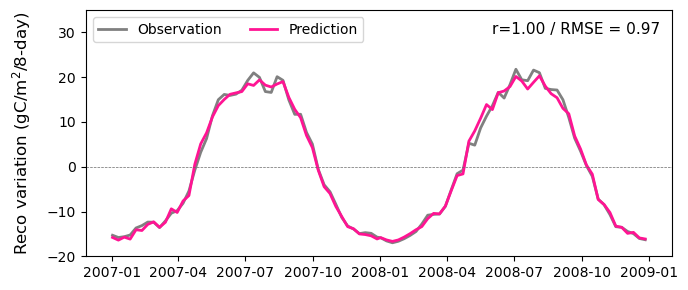

In [32]:
#--- Read file
real_weighted = labl.weighted(weights)
ts_real = real_weighted.mean(("lon", "lat")).sel(time=slice(csdate,cedate))
pred_weighted = pred.weighted(weights)
ts_pred = pred_weighted.mean(("lon", "lat")).sel(time=slice(csdate,cedate))

#--- Time axis
ts_real_g = ts_real.convert_calendar('proleptic_gregorian')
ts_pred_g = ts_pred.convert_calendar('proleptic_gregorian')

#--- Evaluation
df = xr.merge([ts_real_g.rename('real'), ts_pred_g.rename('pred')]).to_dataframe().dropna()
corr = df['real'].corr(df['pred'])
rmse = np.sqrt(((df['real'] - df['pred'])**2).mean())

# --- Plot
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(df.index, df['real'].values, color='grey', lw=2, label='Observation')
ax.plot(df.index, df['pred'].values, color='deeppink',  lw=2, label='Prediction')
ax.axhline(0,linestyle='--',c='dimgrey',lw=0.5)

# locator = mdates.YearLocator(5)
# formatter = mdates.DateFormatter('%Y')
# ax.xaxis.set_major_locator(locator)
# ax.xaxis.set_major_formatter(formatter)
plt.xticks(rotation=0, fontsize=10)
plt.yticks(fontsize=10)
ax.set_ylim(-20, 35)
ax.set_ylabel(r'Reco variation (gC/m$^2$/8-day)', fontsize=12, labelpad=10)
ax.legend(loc='upper left', ncol=2)
ax.text(0.98, 0.95, f'r={corr:.2f} / RMSE = {rmse:.2f}',
        transform=ax.transAxes, fontsize=11, va='top', ha='right',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='white', alpha=0.8))
plt.tight_layout()
plt.show()

### Spatio-temporal scatter

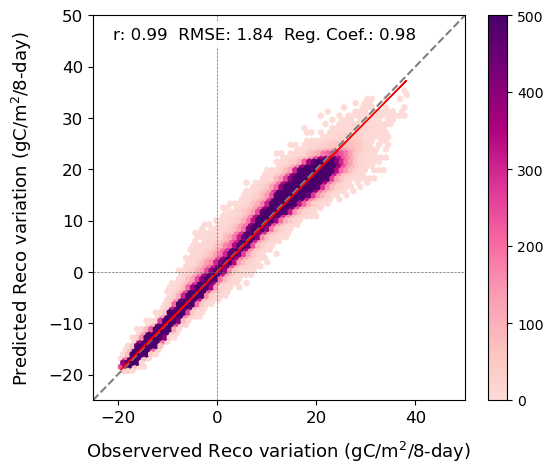

In [5]:
x_wo = labl.data.flatten()
y_wo = pred.data.flatten()
mask_wo = ~np.isnan(x_wo) & ~np.isnan(y_wo)
x_wo = x_wo[mask_wo]
y_wo = y_wo[mask_wo]

#--- Linear regression
X = x_wo.reshape(-1, 1)
reg_wo = LinearRegression().fit(X, y_wo)
y_pred_wo = reg_wo.predict(X)

#--- Evaluation
rmse_wo = f"RMSE: {np.sqrt(np.mean((x_wo - y_wo) ** 2)):.2f}"
corr_wo = f"r: {np.corrcoef(x_wo, y_wo)[0,1]:.2f}"
reg_coef_wo = f"Reg. Coef.: {reg_wo.coef_[0]:.2f}"

#--- Plot
minval = -25 ; maxval = 50
# base_cmap = mpl.colormaps['Greens']
base_cmap = mpl.colormaps['RdPu']
truncated_cmap = mcolors.LinearSegmentedColormap.from_list('trunc_Greens', base_cmap(np.linspace(0.15, 1.0, 256)))
fig, ax = plt.subplots(figsize=(6, 5))
hb = ax.hexbin(x_wo, y_wo, gridsize=80, cmap=truncated_cmap, bins=None, 
               mincnt=0.01, vmin=0, vmax=500, extent=(minval, maxval, minval, maxval))
ax.plot([minval, maxval], [minval, maxval], color='grey', linestyle='--', label='1:1 Line')
ax.plot(x_wo, y_pred_wo, color='red', linestyle='-', linewidth=1, label="Linear Regression Line")
ax.axhline(0,linestyle='--',c='dimgrey',lw=0.5)
ax.axvline(0,linestyle='--',c='dimgrey',lw=0.5)
ax.set_xlim(minval, maxval)
ax.set_ylim(minval, maxval)
ax.set_xlabel("Observerved Reco variation (gC/m$^2$/8-day)", fontsize=13, labelpad=10)
ax.set_ylabel("Predicted Reco variation (gC/m$^2$/8-day)", fontsize=13, labelpad=10)
ax.tick_params(labelsize=12)

textstr = corr_wo + '  ' + rmse_wo + '  ' + reg_coef_wo
ax.text(0.87, 0.93, textstr,
        transform=ax.transAxes,
        fontsize=12,
        verticalalignment='bottom',
        horizontalalignment='right',
        bbox=dict(boxstyle='round', facecolor='white', edgecolor='white', alpha=0.8))

# cb = fig.colorbar(hb, ax=ax,) #label='log10(Density)')
# cbar = plt.colorbar(hb, ax=ax, ticks=[0, 1000, 2000, 3000, 4000, 5000])
cbar = plt.colorbar(hb, ax=ax, ticks=[0, 100, 200, 300, 400, 500])
# cbar.set_label('Counts')  # 컬러바 라벨 설정

plt.show()